<div class="frontmatter text-center">
<h1>Computational Thinking and Statistics — Assessment Template</h1>
<h3>MSc Business Analytics · University of Greenwich · 2026/27</h3>
</div>

## Instructions

Work through every section in order, completing the **code cells** and writing your answers in the **markdown cells - only where specified**. Your submission is
this notebook, **executed**, with your commentary — max 2,000 words of markdown in total.

**The dataset** is `airbnb_london.csv` (see the codebook on Moodle for every variable). Follow the istructions in the codebook and the template here provided.

## Setting up

In [1]:
# Load the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import seaborn as sns
print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
# Load the dataset
df=pd.read_csv('airbnb_london.csv')
print("dataset loaded successfully")

dataset loaded successfully


In [3]:
# Visualise dataset information (size, types, first rows)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.info()
display(df.head())
print ("These are the first five rows of the data")

Number of rows: 96871
Number of columns: 17
<class 'pandas.DataFrame'>
RangeIndex: 96871 entries, 0 to 96870
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    96871 non-null  int64  
 1   name                  96871 non-null  str    
 2   host_since            96830 non-null  str    
 3   host_is_superhost     95105 non-null  str    
 4   neighbourhood         96871 non-null  str    
 5   property_type         96871 non-null  str    
 6   room_type             96871 non-null  str    
 7   accommodates          96871 non-null  int64  
 8   bathrooms             62025 non-null  float64
 9   bedrooms              84096 non-null  float64
 10  beds                  61951 non-null  float64
 11  price                 61963 non-null  str    
 12  minimum_nights        96871 non-null  int64  
 13  number_of_reviews     96871 non-null  int64  
 14  review_scores_rating  72749 non-null 

,id,name,host_since,host_is_superhost,neighbourhood,property_type,room_type,accommodates,bathrooms,bedrooms,beds,price,minimum_nights,number_of_reviews,review_scores_rating,instant_bookable,availability_365
0,13913,Holiday London DB Room Let-on going,2009-11-16,t,Islington,Private room in rental unit,Private room,1,1.0,1.0,1.0,$70.00,1,55,4.85,f,331
1,15400,Bright Chelsea Apartment. Chelsea!,2009-12-05,f,Kensington and Chelsea,Entire rental unit,Entire home/apt,2,1.0,1.0,1.0,$149.00,4,97,4.80,f,199
2,17402,Very Central Modern 3-Bed/2 Bath By Oxford St W1,2010-01-04,t,Westminster,Entire rental unit,Entire home/apt,6,2.0,3.0,3.0,$411.00,3,56,4.77,f,80
3,24328,Battersea live/work artist house,2009-09-28,f,Wandsworth,Entire townhouse,Entire home/apt,2,NaN,1.0,NaN,NaN,7,95,4.90,f,294
4,36274,Bright 1 bedroom apt off brick lane in Shoreditch,2010-05-27,f,Tower Hamlets,Entire condo,Entire home/apt,4,1.0,1.0,0.0,$210.00,5,15,4.53,t,323


These are the first five rows of the data


## Data pre-processing

In [4]:
# Make sure variables are in the correct format.
df['price'] = pd.to_numeric(df['price'].astype(str).str.replace(r'[\$,]', '', regex=True))

In [5]:
# Check for missing values, and handle them (justify your choices in the discussion below).
missing = df.isnull().sum().sort_values(ascending=False)
pct = (missing / len(df) * 100).round(1)
pd.DataFrame({'missing': missing, 'percent': pct}).head(12)

,missing,percent
beds,34920,36.0
price,34908,36.0
bathrooms,34846,36.0
review_scores_rating,24122,24.9
bedrooms,12775,13.2
host_is_superhost,1766,1.8
host_since,41,0.0
id,0,0.0
name,0,0.0
accommodates,0,0.0


In [6]:
price_missing = df['price'].isna()
counts = df.groupby(price_missing).agg(
    listings=('price', 'size'),
    bathrooms_missing=('bathrooms', lambda s: s.isna().sum()),
    beds_missing=('beds', lambda s: s.isna().sum()),
    median_availability=('availability_365', 'median'),
    availability_zero=('availability_365', lambda s: (s == 0).sum()),
)
counts.index = ['Has a price', 'No price']
counts

,listings,bathrooms_missing,beds_missing,median_availability,availability_zero
Has a price,61963,76,129,243.0,832
No price,34908,34770,34791,0.0,30564


In [7]:
df_original = df.copy()
df_clean = df_original
df_clean = df_clean.dropna(subset=['price','host_is_superhost']).copy()

In [8]:
missing = df_clean.isna().sum()
pd.DataFrame({'missing': missing, 'percent': (missing / len(df_clean) * 100).round(1)}).sort_values('missing', ascending=False).head()

,missing,percent
review_scores_rating,13737,22.7
beds,129,0.2
bedrooms,114,0.2
bathrooms,76,0.1
host_since,25,0.0


In [9]:
df_clean = df_clean.dropna(subset=['bathrooms','bedrooms','beds']).copy()
print(f"Columns now: {df_clean.shape[1]}; complete rows: {len(df_clean.dropna()):,} "
      f"({len(df_clean.dropna())/len(df):.0%})")

Columns now: 17; complete rows: 46,711 (48%)


In [10]:
# Check that you dataset contains plausible values for each variable
num_cols = ['price', 'accommodates', 'bedrooms', 'bathrooms', 'beds', 'minimum_nights',
            'number_of_reviews', 'availability_365']
df_clean[num_cols].describe().round(2)

,price,accommodates,bedrooms,bathrooms,beds,minimum_nights,number_of_reviews,availability_365
count,60297.00,60297.00,60297.00,60297.00,60297.00,60297.00,60297.00,60297.00
mean,230.18,3.51,1.55,1.36,1.95,5.06,26.85,215.16
std,4497.89,2.20,1.02,0.72,1.43,18.43,58.43,122.09
min,8.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00
25%,77.00,2.00,1.00,1.00,1.00,1.00,1.00,92.00
50%,135.00,3.00,1.00,1.00,2.00,2.00,7.00,244.00
75%,221.00,4.00,2.00,1.50,2.00,3.00,27.00,335.00
max,1085147.00,16.00,50.00,26.00,50.00,999.00,1902.00,365.00


In [11]:
before = len(df_clean)                     
df_clean = df_clean[df_clean['minimum_nights'] <= 365]   
print(f"Dropped {before - len(df_clean)} rows")      

Dropped 8 rows


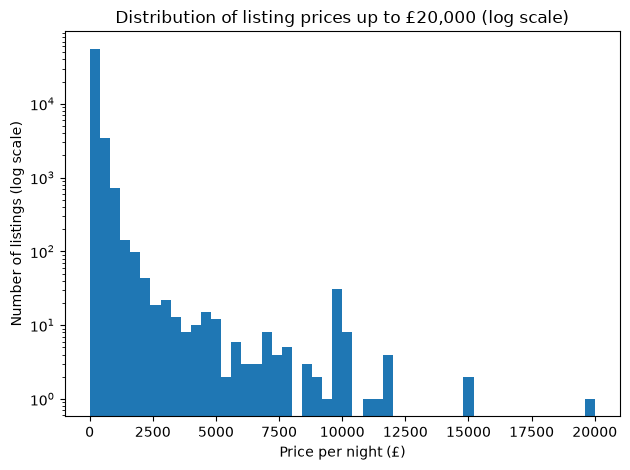

In [12]:
df_clean[df_clean['price'] <= 20000]['price'].plot(kind='hist', bins=50, logy=True, title='Distribution of listing prices up to £20,000 (log scale)')
plt.xlabel('Price per night (£)')
plt.ylabel('Number of listings (log scale)')
plt.tight_layout(); plt.show()

In [13]:
print("£7,000 to £7,500: ", ((df_clean['price'] > 7000) & (df_clean['price'] <= 7500)).sum(), "rows")
print("£7,500 to £8,000: ", ((df_clean['price'] > 7500) & (df_clean['price'] <= 8000)).sum(), "rows")
print("£8,000 to £8,400: ", ((df_clean['price'] > 8000) & (df_clean['price'] <= 8400)).sum(), "rows")
print(df_clean.loc[(df_clean['price'] > 8000) & (df_clean['price'] <= 11000), 'price'].value_counts().head())

£7,000 to £7,500:  5 rows
£7,500 to £8,000:  6 rows
£8,000 to £8,400:  0 rows
price
9999.0     27
10020.0     4
10890.0     1
9680.0      1
10001.0     1
Name: count, dtype: int64


In [14]:
df_clean.loc[df_clean['price'] > 8000, ['name', 'room_type', 'accommodates', 'bedrooms', 'price']].sort_values('price', ascending=False).head(10)

,name,room_type,accommodates,bedrooms,price
83405,Lux 2 Bed in Canary Wharf close to Excel & O2,Entire home/apt,1,1.0,1085147.0
10228,Bright & airy DoubleBed with EnSuite in Zone 2!,Entire home/apt,6,2.0,74100.0
77023,Walk To London Eye,Private room,2,1.0,66189.0
54442,Close To London Eye,Private room,2,1.0,65000.0
57204,Close to London Eye (BOL),Private room,3,1.0,58000.0
75312,Very Central Room - Walk to Eye,Private room,3,1.0,58000.0
9489,No Longer Available,Private room,1,1.0,53588.0
38591,SHORT WALK TO LONDON EYE - DOUBLE ROOM (SUR),Private room,3,1.0,50000.0
51162,Twin Room Close to London Eye (RHI),Private room,3,1.0,50000.0
63728,"Spacious, airy penthouse with stunning view",Entire home/apt,3,2.0,30812.0


In [15]:
before = len(df_clean)
df_clean = df_clean[df_clean['price'] <= 8000]
print(f"Dropped {before - len(df_clean)} rows above 8,000; {len(df_clean):,} remain")

Dropped 68 rows above 8,000; 60,221 remain


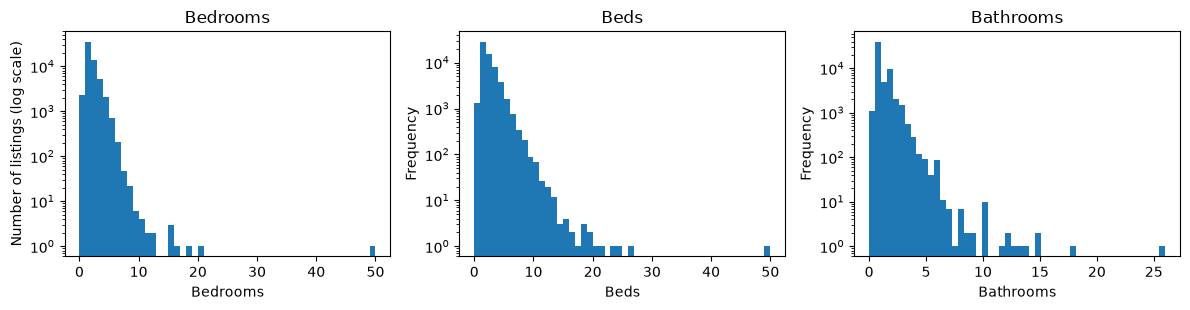

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
df_clean['bedrooms'].plot(kind='hist', bins=50, ax=axes[0], logy=True, title='Bedrooms')
df_clean['beds'].plot(kind='hist', bins=50, ax=axes[1], logy=True, title='Beds')
df_clean['bathrooms'].plot(kind='hist', bins=50, ax=axes[2], logy=True, title='Bathrooms')
for ax, name in zip(axes, ['Bedrooms', 'Beds', 'Bathrooms']):
    ax.set_xlabel(name)
axes[0].set_ylabel('Number of listings (log scale)')
plt.tight_layout(); plt.show()

In [17]:
print("Bedrooms above 13:  ", (df_clean['bedrooms'] > 13).sum(), "rows")
print("Beds above 22:      ", (df_clean['beds'] > 22).sum(), "rows")
print("Bathrooms above 10: ", (df_clean['bathrooms'] > 10).sum(), "rows")
df_clean.loc[(df_clean['bedrooms'] > 13) | (df_clean['beds'] > 22) | (df_clean['bathrooms'] > 10), ['name', 'room_type', 'accommodates', 'bedrooms', 'beds', 'bathrooms', 'price']].sort_values('bedrooms', ascending=False).head(10)

Bedrooms above 13:   7 rows
Beds above 22:       4 rows
Bathrooms above 10:  10 rows


,name,room_type,accommodates,bedrooms,beds,bathrooms,price
69467,Choice of properties | perfect for business gr...,Entire home/apt,16,50.0,50.0,15.0,175.0
61367,Hotel261,Private room,2,20.0,1.0,0.5,119.0
62035,18 Bedrooms/ 18 Bathrooms/ 3 Full houses together,Entire home/apt,16,18.0,19.0,18.0,3000.0
87921,Luxury on Lock: Four Bespoke Houses,Entire home/apt,16,16.0,26.0,13.5,1219.0
60228,Hilldrop Apartments - 14 Self Contained Apartm...,Entire home/apt,16,15.0,1.0,14.0,1538.0
79361,Widegate Residential Hotel,Private room,2,15.0,15.0,15.0,169.0
73985,3 FULL houses/ 15BR/ 5min walk tube/ lots stors,Entire home/apt,16,15.0,18.0,12.0,1300.0
37079,The Finsbury Guesthouse . New and Refurbished,Hotel room,10,12.0,10.0,12.5,290.0
29911,12 Bedroom House Just Minutes from Heathrow,Entire home/apt,16,12.0,14.0,12.0,500.0
15693,2 houses/LargeGroup Sleeps32,Entire home/apt,16,11.0,23.0,6.5,3536.0


In [18]:
before = len(df_clean)
df_clean = df_clean[(df_clean['bedrooms'] <= 13) & (df_clean['beds'] <= 22) & (df_clean['bathrooms'] <= 10)]
print(f"Dropped {before - len(df_clean)} rows with more than 13 bedrooms, 22 beds or 10 bathrooms; {len(df_clean):,} remain")

Dropped 13 rows with more than 13 bedrooms, 22 beds or 10 bathrooms; 60,208 remain


In [19]:
# Encode categorical variables ready for modelling.

df_clean['has_rating'] = (df_clean['number_of_reviews'] > 0).astype(int)

df_clean['host_is_superhost'] = df_clean['host_is_superhost'].map({'t': 1, 'f': 0}).astype(int)
df_clean['instant_bookable']  = df_clean['instant_bookable'].map({'t': 1, 'f': 0}).astype(int)

top = df_clean['property_type'].value_counts().head(10).index
df_clean['property_type'] = df_clean['property_type'].where(df_clean['property_type'].isin(top), 'Other')

df_clean = pd.get_dummies(df_clean, columns=['room_type', 'property_type'], drop_first=True, dtype=int)

df_clean = df_clean.drop(columns=['id', 'name','host_since','review_scores_rating'])
df_clean.columns = df_clean.columns.str.replace(r'[^0-9a-zA-Z_]', '_', regex=True)

print(df_clean.shape)
df_clean.head()

(60208, 25)


,host_is_superhost,neighbourhood,accommodates,bathrooms,bedrooms,beds,price,minimum_nights,number_of_reviews,instant_bookable,...,property_type_Entire_home,property_type_Entire_rental_unit,property_type_Entire_serviced_apartment,property_type_Entire_townhouse,property_type_Other,property_type_Private_room_in_condo,property_type_Private_room_in_home,property_type_Private_room_in_rental_unit,property_type_Private_room_in_townhouse,property_type_Room_in_hotel
0,1,Islington,1,1.0,1.0,1.0,70.0,1,55,0,...,0,0,0,0,0,0,0,1,0,0
1,0,Kensington and Chelsea,2,1.0,1.0,1.0,149.0,4,97,0,...,0,1,0,0,0,0,0,0,0,0
2,1,Westminster,6,2.0,3.0,3.0,411.0,3,56,0,...,0,1,0,0,0,0,0,0,0,0
4,0,Tower Hamlets,4,1.0,1.0,0.0,210.0,5,15,1,...,0,0,0,0,0,0,0,0,0,0
5,0,Richmond upon Thames,5,1.5,3.0,3.0,280.0,3,116,0,...,0,0,0,1,0,0,0,0,0,0


## Discussion

- What is the goal of this analysis?
- Justify the steps taken for handling missing values and other changes you made to the dataset



**Goal of the analysis**

The aim is to identify which factors drive Airbnb listing prices in London, using correlation analysis, simple linear regression and multiple linear regression.

**Handling missing values**

- **`price` (34,908 rows, 36%):** these are inactive listings (99.6% also lack beds and bathrooms), so the missing price is structural. The rows were removed because price is the outcome and imputing it would distort relationships.
- **`host_is_superhost` (1.8%):** it has only two values, 't' or 'f', a missing value can't be filled with a sensible estimate, it was later removed.
- **`bedrooms`, `beds`, `bathrooms` (0.2%, 0.2% and 0.1%):** removed. Once unpriced listings are gone, each is under 5% missing, so deleting these rows causes no meaningful harm.
- **`review_scores_rating` (13,908 rows, 22.4%):** the missingness is structural, not random, so a blank is information, not an error.

**Other changes made to dataset**

- **Data type conversion:** Price was converted from string to numeric.
- **New variables:** The indicator `has_rating` was created to replace `review_scores_rating`.
- **Columns dropped:** `id`, `name`, `host_since` and `review_scores_rating` (not usable predictors).
- **Grouping and encoding:** Property type limited to the ten most common types plus "Other". Room type and property type were **one-hot encoded** into 0/1 columns, leaving one category out each as the reference group (`Entire home/apt` for room type) to avoid the dummy-variable trap. `Neighbourhood` is kept as a single categorical variable and enters the model (Model 2) with `Barking and Dagenham`, as the reference group.

**Price Outliers:** `Price` is heavily right-skewed and the maximum is £1,085,147. To locate the outliers in `price`, a histogram was plotted of prices up to £20,000 with a log scale on the counts. It showed a long thin tail and an unusual spike near £10,000. Counting confirmed it: 27 listings sit at exactly £9,999, with none between £8,000 and £8,400.
- Ten listings above £8,000 were checked: Seven are private rooms for 1 to 3 guests priced between £50,000 and £66,189, one is titled "No Longer Available", and another is titled "2 Bed" but records 1 bedroom, 1 guest and a price of £1,085,147, these prices are implausible.
- Prices above £8,000 (68 rows) were removed, keeping genuine premium listings below that level. The £8,000 cut-off is a judgement call so some unusual prices may still remain below it.

**Minimum nights:** stays above 365 nights were removed (8 rows), because a listing cannot be booked for more than a year.

**Property size outliers:** Listings with more than 13 bedrooms, 22 beds or 10 bathrooms were removed. The cut-offs sit where the value counts show ordinary values ending and isolated single listings beginning.
- Their names show multi-property or hotel-style listings ("3 Full houses together", "14 Self Contained Apartments") and values such as 50 bedrooms exceed the maximum of 16 accommodates and also for private rooms for 2 guests with 20 and 15 bedrooms.


## Data exploration

In [20]:
# Produce descriptive statistics for the variables relevant to your research question.
num_cols = ['price', 'accommodates', 'bedrooms', 'bathrooms', 'beds', 'minimum_nights',
            'has_rating','host_is_superhost','instant_bookable','availability_365']
df_clean[num_cols].describe().round(2)

,price,accommodates,bedrooms,bathrooms,beds,minimum_nights,has_rating,host_is_superhost,instant_bookable,availability_365
count,60208.00,60208.00,60208.00,60208.00,60208.00,60208.00,60208.00,60208.00,60208.00,60208.00
mean,192.75,3.51,1.55,1.35,1.95,4.98,0.78,0.24,0.36,215.10
std,279.82,2.19,0.98,0.68,1.39,17.09,0.42,0.43,0.48,122.08
min,8.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,77.00,2.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,92.00
50%,135.00,3.00,1.00,1.00,2.00,2.00,1.00,0.00,0.00,244.00
75%,221.00,4.00,2.00,1.50,2.00,3.00,1.00,0.00,1.00,335.00
max,8000.00,16.00,10.00,10.00,21.00,365.00,1.00,1.00,1.00,365.00


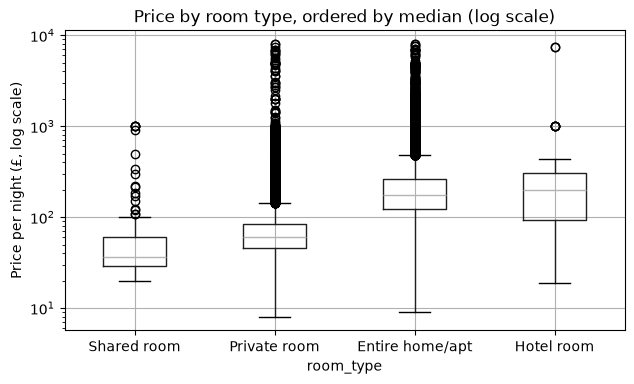

In [21]:
raw = pd.read_csv('airbnb_london.csv', usecols=['room_type'])
df_plot = df_clean[['price']].assign(room_type=raw.loc[df_clean.index, 'room_type'])

order = df_plot.groupby('room_type')['price'].median().sort_values().index
df_plot['room_type'] = pd.Categorical(df_plot['room_type'], categories=order, ordered=True)
df_plot.boxplot(column='price', by='room_type', figsize=(7, 4))
plt.yscale('log'); plt.suptitle('')
plt.title('Price by room type, ordered by median (log scale)'); plt.ylabel('Price per night (£, log scale)')
plt.show()

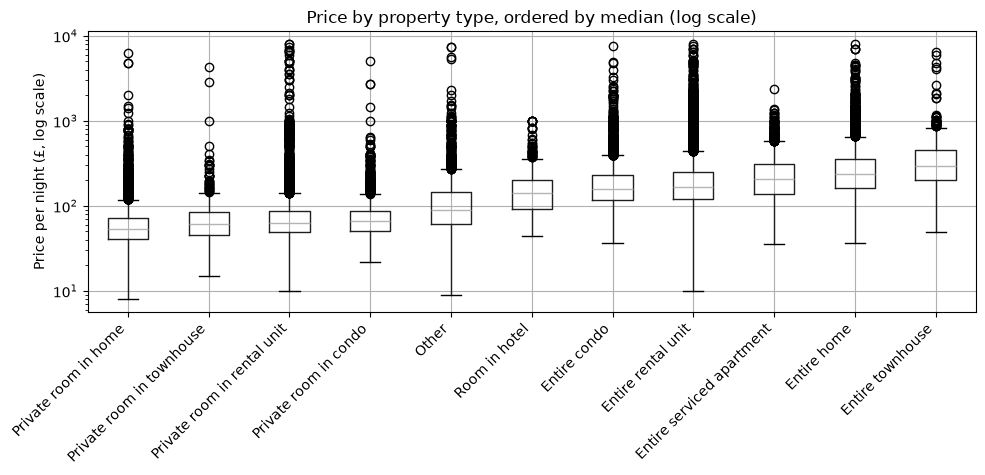

In [22]:
pt = df_clean.filter(like='property_type_')
df_plot = df_clean[['price']].assign(property_type=pt.idxmax(axis=1).str.replace('property_type_', '').str.replace('_', ' ').where(pt.sum(axis=1) > 0, 'Entire condo'))
order = df_plot.groupby('property_type')['price'].median().sort_values().index
df_plot['property_type'] = pd.Categorical(df_plot['property_type'], categories=order, ordered=True)

df_plot.boxplot(column='price', by='property_type', figsize=(10, 5))
plt.yscale('log'); plt.suptitle('')
plt.xticks(rotation=45, ha='right')
plt.title('Price by property type, ordered by median (log scale)'); plt.xlabel(''); plt.ylabel('Price per night (£, log scale)')
plt.tight_layout(); plt.show()

In [23]:
# Property type vs room type: how much do they overlap?
raw = pd.read_csv('airbnb_london.csv', usecols=['room_type', 'property_type']).loc[df_clean.index]
top = raw['property_type'].value_counts().head(10).index
raw['property_type'] = raw['property_type'].where(raw['property_type'].isin(top), 'Other')

ct = pd.crosstab(raw['property_type'], raw['room_type'])
one_type = (ct > 0).sum(axis=1) == 1          # property types that sit in only one room type
n_match = ct[one_type].sum().sum()
print(f"{n_match:,} of {len(raw):,} listings ({n_match/len(raw):.1%}) are in a property type that matches exactly one room type")
print("Extra dummy columns if property type were added:", raw['property_type'].nunique() - 1)

pd.crosstab(raw['property_type'], raw['room_type'], margins=True)

57,316 of 60,208 listings (95.2%) are in a property type that matches exactly one room type
Extra dummy columns if property type were added: 10


room_type,Entire home/apt,Hotel room,Private room,Shared room,All
property_type,,,,,
Entire condo,5572,0,0,0,5572
Entire home,5811,0,0,0,5811
Entire rental unit,26596,0,0,0,26596
Entire serviced apartment,1634,0,0,0,1634
Entire townhouse,582,0,0,0,582
Other,974,56,1214,136,2380
Private room in condo,0,0,2239,0,2239
Private room in home,0,0,7299,0,7299
Private room in rental unit,0,0,6904,0,6904


In [24]:
t = df_clean.groupby('neighbourhood')['price'].agg(count='count', median_price='median').sort_values('median_price', ascending=False).round(0)
pd.concat([t.head(5), t.tail(5)])

,count,median_price
neighbourhood,,
City of London,413,246.0
Kensington and Chelsea,4519,227.0
Westminster,8090,221.0
Camden,4124,162.0
Hammersmith and Fulham,2606,144.0
Harrow,452,74.0
Sutton,360,74.0
Croydon,1171,72.0
Bexley,492,70.0


In [25]:
# Produce a correlation matrix.
df_clean['log_price'] = np.log1p(df_clean['price'])                  
log_cols = ['log_price', 'accommodates', 'bedrooms', 'beds', 'bathrooms', 'minimum_nights',
        'host_is_superhost', 'instant_bookable', 'has_rating','room_type_Private_room', 'room_type_Shared_room', 'room_type_Hotel_room','availability_365']
corr_log = df_clean[log_cols].corr().round(2)
corr_log

,log_price,accommodates,bedrooms,beds,bathrooms,minimum_nights,host_is_superhost,instant_bookable,has_rating,room_type_Private_room,room_type_Shared_room,room_type_Hotel_room,availability_365
log_price,1.00,0.60,0.52,0.46,0.38,0.04,0.03,0.13,-0.10,-0.61,-0.06,0.01,0.07
accommodates,0.60,1.00,0.78,0.82,0.51,-0.00,0.01,0.12,0.01,-0.49,0.01,-0.02,0.04
bedrooms,0.52,0.78,1.00,0.74,0.61,0.02,0.00,0.01,-0.03,-0.33,-0.02,-0.02,0.02
beds,0.46,0.82,0.74,1.00,0.48,0.00,0.00,0.09,0.01,-0.35,0.07,-0.01,0.04
bathrooms,0.38,0.51,0.61,0.48,1.00,0.01,0.02,0.01,-0.03,-0.13,0.01,0.01,0.02
minimum_nights,0.04,-0.00,0.02,0.00,0.01,1.00,0.01,-0.01,-0.08,-0.06,-0.01,-0.01,0.04
host_is_superhost,0.03,0.01,0.00,0.00,0.02,0.01,1.00,-0.06,0.20,0.03,-0.02,-0.01,-0.08
instant_bookable,0.13,0.12,0.01,0.09,0.01,-0.01,-0.06,1.00,0.03,-0.14,0.03,0.03,0.08
has_rating,-0.10,0.01,-0.03,0.01,-0.03,-0.08,0.20,0.03,1.00,-0.03,0.00,0.00,-0.17
room_type_Private_room,-0.61,-0.49,-0.33,-0.35,-0.13,-0.06,0.03,-0.14,-0.03,1.00,-0.03,-0.02,0.02


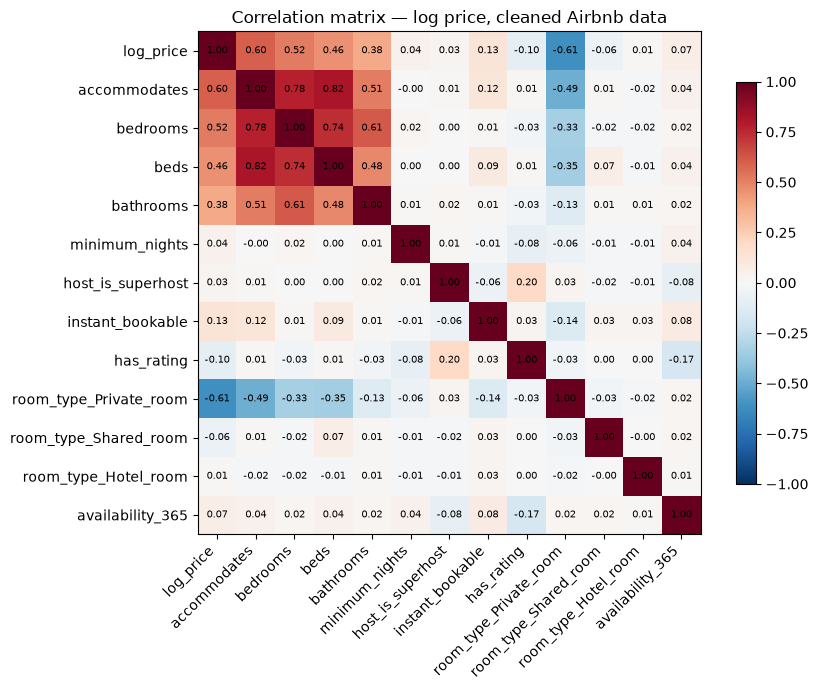

In [26]:
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_log, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(log_cols))); ax.set_xticklabels(log_cols, rotation=45, ha='right')
ax.set_yticks(range(len(log_cols))); ax.set_yticklabels(log_cols)
for i in range(len(log_cols)):
    for j in range(len(log_cols)):
        ax.text(j, i, f"{corr_log.iloc[i, j]:.2f}", ha='center', va='center', fontsize=7)
plt.colorbar(im, shrink=0.8)
plt.title('Correlation matrix — log price, cleaned Airbnb data')
plt.tight_layout(); plt.show()

## Discussion

- Based on the exploration, which predictors look most promising for your chosen research question, and why?
- Discuss any issues (if any) you found during the exploration.



**Most promising predictors**

- **Predictors** `accommodates`(r = 0.60 with log price) and `room_type_Private_room` (r = −0.61) have the strongest correlations. `bedrooms` (0.52), `beds` (0.46) and `bathrooms` (0.38) are moderate.
- **Room type:** boxplots ordered by median show entire homes and hotel rooms are priced well above private and shared rooms.
- **neighbourhood:** median prices are highest in the City of London (£246), Kensington and Chelsea (£227) and Westminster (£221), and lowest in outer boroughs such as Bexley (£70) and Hillingdon (£69).

**Issues found**
- **Log price:** The boxplots use a log scale and the correlation matrix uses **log price**. Price is right-skewed, so a few very expensive listings would dominate the plots and distort Pearson correlations. Log price is used in the assumption checks and in all later models
- **Multicollinearity:** `accommodates`, `bedrooms` and `beds` are strongly inter-correlated. Using them together could make regression coefficients unstable, so this will be checked with VIF.
- **Limits of correlation:** It shows linear association only, not causation. `neighbourhood`(location) is not in the matrix, because 33 boroughs would make it unreadable, so it is examined separately through the median price by borough and is modelled later.
- **Property type:** `property_type` was not put in the correlation matrix or the regression models. It mostly repeats room type: 57,316 of the 60,208 listings (95.2%) have a property type that matches exactly one room type. It would also add ten more dummy columns. It is shown only in the boxplot.

## Simple linear regression

In [27]:
# Run a SIMPLE linear regression between your chosen DV and its single main predictor (IV).

import statsmodels.formula.api as smf
simple = smf.ols('log_price ~ accommodates', data=df_clean).fit()
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.362
Model:                            OLS   Adj. R-squared:                  0.362
Method:                 Least Squares   F-statistic:                 3.411e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:30:55   Log-Likelihood:                -56452.
No. Observations:               60208   AIC:                         1.129e+05
Df Residuals:                   60206   BIC:                         1.129e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        4.1714      0.005    877.172   

## Comment the Output

- Interpret the output of the regression (at minimum: coefficient, R squared)



**Coefficient:** The slope on `accommodates` is 0.2121 (95% CI 0.210 to 0.214). Because the outcome is log price: each additional guest is associated with an approximately 24% higher price. 

**R²:** R² = 0.362, so `accommodates` alone explains about 36% of the variation in log price. The other 64%  must come from other factors.

**Significance:** the effect is significant (p < 0.05, n = 60,208). Association, not a cause.

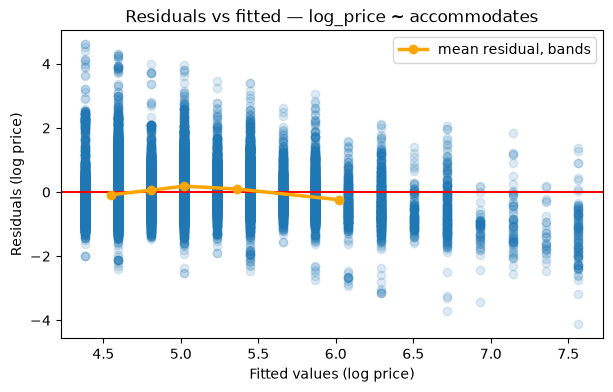

,mean_fitted,mean_resid,sd_resid,n
"(4.383, 4.596]",4.55,-0.08,0.63,28335
"(4.596, 4.808]",4.81,0.06,0.55,4751
"(4.808, 5.02]",5.02,0.19,0.56,12582
"(5.02, 5.444]",5.36,0.10,0.56,9669
"(5.444, 7.566]",6.02,-0.24,0.71,4871


In [28]:
# Test the 4 assumptions of linear regression for your simple model:
#  1) linearity      2) independence of errors
#  3) homoscedasticity (constant variance)      4) normality of residuals

#  Assumption 1: linearity 
fitted = simple.fittedvalues
resid = simple.resid

bands = pd.qcut(fitted, 8, duplicates='drop')
check = (pd.DataFrame({'fitted': fitted, 'resid': resid})
           .groupby(bands, observed=True)
           .agg(mean_fitted=('fitted', 'mean'), mean_resid=('resid', 'mean'), sd_resid=('resid', 'std'), n=('resid', 'size')))

plt.figure(figsize=(7, 4))
plt.scatter(fitted, resid, alpha=0.15)
plt.axhline(0, color='red')
plt.plot(check['mean_fitted'], check['mean_resid'], color='orange', marker='o', lw=2.5, label='mean residual, bands')
plt.xlabel('Fitted values (log price)'); plt.ylabel('Residuals (log price)'); plt.legend()
plt.title('Residuals vs fitted — log_price ~ accommodates')
plt.show()
check.round(2)

In [29]:
# Assumption 2: independence
from statsmodels.stats.stattools import durbin_watson
print("Durbin-Watson, rows in file order:", round(durbin_watson(resid), 3))
print("Durbin-Watson, rows shuffled:     ", round(durbin_watson(resid.sample(frac=1, random_state=1)), 3))

nbhd = df_clean['neighbourhood']
by_nbhd = resid.groupby(nbhd).agg(['mean', 'size']).round(2).sort_values('mean')
by_nbhd.columns = ['mean residual (log price)', 'listings']
pd.concat([by_nbhd.head(3), by_nbhd.tail(3)])

Durbin-Watson, rows in file order: 1.77
Durbin-Watson, rows shuffled:      1.991


,mean residual (log price),listings
neighbourhood,,
Bexley,-0.50,492
Barking and Dagenham,-0.47,540
Croydon,-0.47,1171
Westminster,0.41,8090
Kensington and Chelsea,0.49,4519
City of London,0.68,413


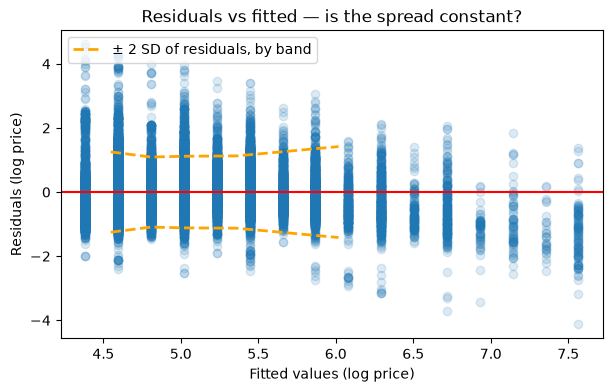

SD of residuals: lowest band 0.63   highest band 0.71   ratio 1.1x


In [30]:
# Assumption 3: Constant variance  
plt.figure(figsize=(7, 4))
plt.scatter(fitted, resid, alpha=0.15)
plt.axhline(0, color='red')
plt.plot(check['mean_fitted'],  2 * check['sd_resid'], color='orange', ls='--', lw=2, label='± 2 SD of residuals, by band')
plt.plot(check['mean_fitted'], -2 * check['sd_resid'], color='orange', ls='--', lw=2)
plt.xlabel('Fitted values (log price)'); plt.ylabel('Residuals (log price)'); plt.legend(loc='upper left')
plt.title('Residuals vs fitted — is the spread constant?')
plt.show()

lo, hi = check['sd_resid'].iloc[0], check['sd_resid'].iloc[-1]
print(f"SD of residuals: lowest band {lo:.2f}   highest band {hi:.2f}   ratio {hi/lo:.1f}x")

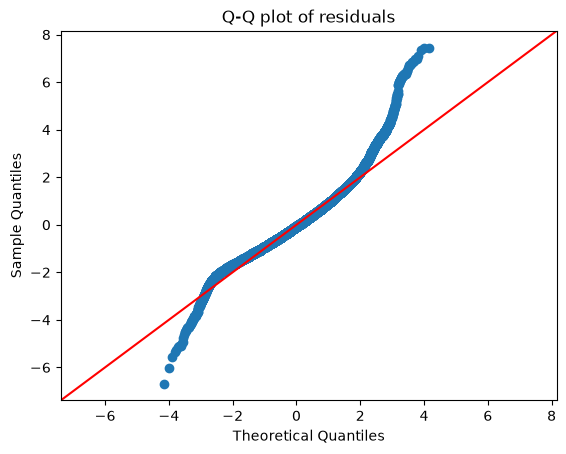

Skew:      0.718   (bell curve: 0)
Kurtosis:  5.607   (bell curve: 3)
Omnibus normality test, p-value: 0.0e+00


In [31]:
# Assumption 4: Normality
import statsmodels.api as sm
from scipy import stats

sm.qqplot(resid, line='45', fit=True)
plt.title('Q-Q plot of residuals')
plt.show()

print(f"Skew:     {stats.skew(resid):6.3f}   (bell curve: 0)")
print(f"Kurtosis: {stats.kurtosis(resid, fisher=False):6.3f}   (bell curve: 3)")
print(f"Omnibus normality test, p-value: {sm.stats.omni_normtest(resid)[1]:.1e}")

In [32]:
# Exogeneity: add one plausible confounder (room type) and watch the slope on accommodates
with_room = smf.ols('log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room', data=df_clean).fit()
print(f"Slope on accommodates, alone:           {simple.params['accommodates']:.3f}  (about {np.exp(simple.params['accommodates'])-1:.1%} per guest)")
print(f"Slope on accommodates, with room type:  {with_room.params['accommodates']:.3f}  (about {np.exp(with_room.params['accommodates'])-1:.1%} per guest)")
print("Correlation of accommodates with each room type:")
print(df_clean[['accommodates', 'room_type_Private_room', 'room_type_Shared_room', 'room_type_Hotel_room']].corr()['accommodates'].drop('accommodates').round(2))

Slope on accommodates, alone:           0.212  (about 23.6% per guest)
Slope on accommodates, with room type:  0.140  (about 15.1% per guest)
Correlation of accommodates with each room type:
room_type_Private_room   -0.49
room_type_Shared_room     0.01
room_type_Hotel_room     -0.02
Name: accommodates, dtype: float64


## Comment the Output

- Which assumptions hold? 
- Which are violated?
- What would you do about it?



**Which assumptions hold?**
- **Linearity: mostly met.** The band means of the residuals stay close to zero (−0.08 to +0.19), with a small dip in the top price band (−0.24). The slope is usable.
- **Constant variance: met.** The typical error is similar across fitted values (SD 0.55 to 0.71, a ratio of about 1.3, with a mild widening in the top band).

**Which are violated?**
- **Independence: not met.** Durbin-Watson is 1.77 in file order but 1.99 once shuffled, and whole boroughs sit on one side of the line (mean residual from −0.50 in Bexley to +0.68 in City of London). The slope is not biased, but the standard errors are too small.
- **Normality: not met on paper, harmless here.** Skew is 0.72 and kurtosis 5.61 (bell curve: 0 and 3), and the Q-Q plot bends at both ends. With n = 60,208 the central limit theorem protects the p-values. The extreme residuals are the premium listings, which were kept on purpose.
- **Exogeneity: not met for a causal reading.** Room type was added as a plausible hidden driver of price that also differs with the number of guests a listing sleeps. With room type in the model, the slope on accommodates falls from 0.212 (about 23.6% per guest) to 0.140 (about 15%), so the simple slope overstates the effect of size.

**What would be done about it?**
- Independence: add neighbourhood (Model 2), which absorbs part of the clustering by borough. Some dependence remains and is stated as a limit of the analysis.
- Exogeneity: add room type in Model 1, and describe results as "associated with", never "causes".
- Normality: no action needed at this sample size.

### Multiple linear regression

In [33]:
# Model 1: extend your simple model by adding a second predictor.
model1 = smf.ols('log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room',
                 data=df_clean).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.501
Model:                            OLS   Adj. R-squared:                  0.501
Method:                 Least Squares   F-statistic:                 1.510e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:30:57   Log-Likelihood:                -49047.
No. Observations:               60208   AIC:                         9.810e+04
Df Residuals:                   60203   BIC:                         9.815e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  4

## Comment the Output

- What changes when you add this predictor? Interpret the new coefficient and regression fit.



**New predictor:** Room type was added as three dummy variables, with `Entire home/apt` as the reference group. Compared with an entire home of the same capacity, the price is approximately 50% lower for a private room (−0.6998), approximately 74% lower for a shared room (−1.3334) and approximately 27% higher for a hotel room (+0.2380), all with p < 0.01. The hotel and shared-room intervals are wider (hotel 0.096 to 0.380), which reflects how few such listings there are.

**Effect on the first coefficient:** the slope on accommodates falls from 0.2121 (about 24% per guest) to 0.1402 (about 15% per guest). Part of what the simple model attributed to guest count belongs to room type.

**Fit:** R² rises from 0.362 to 0.501 (adjusted R² 0.501), so about half of the variation in log price is now explained. The gain is large, which supports keeping room type. The results are associations, not causal effects.

In [34]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def vif_table(data, cols):
    X = data[cols].assign(const=1)
    return pd.DataFrame({'variable': cols,
                         'VIF': [round(variance_inflation_factor(X.values, i), 2)
                                 for i in range(len(cols))]})

good = ['accommodates', 'bedrooms','room_type_Private_room', 'room_type_Shared_room', 'room_type_Hotel_room',
        'bathrooms', 'minimum_nights', 'host_is_superhost', 'instant_bookable', 'has_rating','availability_365']
bad  = good + [ 'beds']

print("Sensible model:"); print(vif_table(df_clean, good).to_string(index=False))
print()
print("With beds added:"); print(vif_table(df_clean, bad).to_string(index=False))

Sensible model:
              variable  VIF
          accommodates 3.19
              bedrooms 3.13
room_type_Private_room 1.37
 room_type_Shared_room 1.01
  room_type_Hotel_room 1.00
             bathrooms 1.62
        minimum_nights 1.01
     host_is_superhost 1.05
      instant_bookable 1.06
            has_rating 1.08
      availability_365 1.05

With beds added:
              variable  VIF
          accommodates 4.49
              bedrooms 3.39
room_type_Private_room 1.38
 room_type_Shared_room 1.02
  room_type_Hotel_room 1.00
             bathrooms 1.62
        minimum_nights 1.01
     host_is_superhost 1.05
      instant_bookable 1.06
            has_rating 1.08
      availability_365 1.05
                  beds 3.35


In [35]:
candidates = {
    'M1: accommodates':        'log_price ~ accommodates',
    'M2: + room type':         'log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room',
    'M3: + bathrooms':         'log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room + bathrooms',
    'M4: + has_rating':        'log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room + bathrooms + has_rating',
    'M5: + host_is_superhost': 'log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room + bathrooms + has_rating + host_is_superhost',
    'M6: + bedrooms':          'log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room + bathrooms + has_rating + host_is_superhost + bedrooms',
    'M7: + neighbourhood':     'log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room + bathrooms + has_rating + host_is_superhost + bedrooms + C(neighbourhood)',
    'M8: + instant_bookable':  'log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room + bathrooms + has_rating + host_is_superhost + bedrooms + C(neighbourhood) + instant_bookable',
    'M9: + minimum_nights':    'log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room + bathrooms + has_rating + host_is_superhost + bedrooms + C(neighbourhood) + instant_bookable + minimum_nights',
    'M10: + availability_365': 'log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room + bathrooms + has_rating + host_is_superhost + bedrooms + C(neighbourhood) + instant_bookable + minimum_nights + availability_365',
}
results = pd.DataFrame([
    {'model': name, 'adj_R2': round(smf.ols(f, data=df_clean).fit().rsquared_adj, 3),
     'n_predictors': f.count('+') + 1}
    for name, f in candidates.items()
])
results['gain'] = results['adj_R2'].diff().round(3)
results

,model,adj_R2,n_predictors,gain
0,M1: accommodates,0.362,1,NaN
1,M2: + room type,0.501,4,0.139
2,M3: + bathrooms,0.521,5,0.020
3,M4: + has_rating,0.532,6,0.011
4,M5: + host_is_superhost,0.536,7,0.004
5,M6: + bedrooms,0.539,8,0.003
6,M7: + neighbourhood,0.627,9,0.088
7,M8: + instant_bookable,0.627,10,0.000
8,M9: + minimum_nights,0.627,11,0.000
9,M10: + availability_365,0.632,12,0.005


In [36]:
model2 = smf.ols('log_price ~ accommodates + room_type_Private_room + room_type_Shared_room + room_type_Hotel_room + bathrooms + bedrooms + has_rating + host_is_superhost + availability_365 + C(neighbourhood)', 
                 data=df_clean).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.632
Model:                            OLS   Adj. R-squared:                  0.632
Method:                 Least Squares   F-statistic:                     2523.
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:31:02   Log-Likelihood:                -39851.
No. Observations:               60208   AIC:                         7.979e+04
Df Residuals:                   60166   BIC:                         8.016e+04
Df Model:                          41                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

## Comment the Output

- Which predictors are statistically significant? Interpret two of them.


**How the variables were chosen:** The VIF was used to avoid a kitchen-sink model. `accommodates`, `bedrooms` and `beds` are strongly related, and adding `beds` pushed the VIF of `accommodates` from 3.19 to 4.49, close to 5 which is a concern level. `beds` was left out. Variables were then added one at a time and kept only if they improved adjusted R². Room type gave by far the largest gain (+0.139), `availability_365` added +0.005, and `instant_bookable` (0.000) and `minimum_nights` (0.000) were the lowest contributors and did not earn their place.

**Significant (p < 0.05):**
- Eight predictors have p < 0.05: `accommodates` (0.0689), `room_type_Private_room` (−0.6292), `room_type_Shared_room` (−1.2904), `bathrooms` (0.1072), `bedrooms` (0.1408), `has_rating` (−0.2038), `host_is_superhost` (0.0811) and `availability_365` (0.0005). `room_type_Hotel_room` is not significant (p = 0.330).
- 27 of the 32 borough dummies are significant except five boroughs, Bromley (p = 0.059), Croydon (p = 0.383), Harrow (p = 0.104), Havering (p = 0.252) and Sutton (p = 0.154).

**Interpretation (two predictors):**

- The two strongest are `room_type_Private_room` (t = −127.3) and `accommodates` (t = 44.4), which have the largest t-values.
- **`room_type_Private_room` (−0.6292):** compared with an entire home with the same other features, a private room is priced about 47% lower.
- **`accommodates` (0.0689):** for listings that are otherwise the same, each extra guest goes with a price about 7% higher.

## Compare the three models

In [37]:
# Model comparison: collect the relevant metrics of the 3 models run above and present them in a small table or printout.
# Compare the three models
simple = smf.ols('log_price ~ accommodates', data=df_clean).fit()
pd.DataFrame({'R2': [m.rsquared for m in (simple, model1, model2)],
              'adj_R2': [m.rsquared_adj for m in (simple, model1, model2)],
              'AIC': [m.aic for m in (simple, model1, model2)],
              'n_predictors': [len(m.params) - 1 for m in (simple, model1, model2)]},
             index=['simple', 'model1', 'model2']).round(3)

,R2,adj_R2,AIC,n_predictors
simple,0.362,0.362,112908.916,1
model1,0.501,0.501,98104.992,4
model2,0.632,0.632,79785.024,41


## Discussion

- Which model is best, and why? Distinguish statistical significance from practical importance, and comment on the size of the key effects.



**Which model is best:** Model 2 is the best of the three. Its adjusted R² is the highest (0.362 → 0.501 → 0.632). The gain is large at each step, each variable was added only after its adjusted R² gain was checked, so it is not a kitchen-sink model. The cost is 41 coefficients (room type = 3 dummy columns and `neighbourhood` = 32). Listings in the same borough were being over- or under-predicted together, and adding `neighbourhood` raised adjusted R² by 0.088.

**Significance vs practical importance:** 

- **Model 2 (significant and important):** Private room is about 46.7% cheaper and a shared room about 72.5% cheaper than an entire home/apt (p < 0.001). These are not due to chance. 
- Each extra bedroom goes with about 15.1% higher price and each extra bathroom with about 11.3% higher (both p < 0.001). Every listing has these values, so they are measured precisely.
- **Model 2 (significant but modest):** In Model 2, each extra guest (`accommodates`) goes with about 7.1% higher price (p < 0.001). The effect is precisely measured, all 60,208 listings contribute to it, smaller next to room type, so it is significant but only modestly.
- **Model 2 (not significant):** The hotel effect (+6.3%) is similar in size to superhost (+8.5%) but not significant (p = 0.330) because only 57 listings support it, while accommodates is small (+7.1% per guest) yet significant (p < 0.001) because 60,208 listings measure it. It was significant in Model 1 (p = 0.001), but Model 2 holds `neighbourhood` fixed and hotel rooms are concentrated in central boroughs.
- Five boroughs are not significantly different in price from the reference borough,`Barking and Dagenham`(p = 0.059 to 0.383), so no clear price gap can be claimed for them. `neighbourhood` is judged as a whole by its adjusted R² gain (+0.088), so location is worth keeping in the model even though five boroughs are not significant.
- **Size of the key effects (Model 2):** Compared with `Barking and Dagenham`, prices are about 151% higher in City of London, 117% in Kensington and Chelsea and 116% in Westminster.
**Caution:** All effects are associations, not causes. Model 2 explains about 63% of the variation in log price, so about 37% is unexplained. The Durbin-Watson value (1.799) shows some dependence remains, so p-values may be slightly too optimistic.

## Conclusion

- Summarise your findings for a non-technical decision-maker: answer your chosen research question, state how confident we should be in the results, and name one limitation of this analysis and one concrete next step.



**Answer:** In London, Airbnb prices are driven mainly by where the listing is and what type of room it is. Compared with Barking and Dagenham, the prices are more than double in City of London, Westminster and Kensington and Chelsea. A private room costs about half as much as an entire home, and a shared room much less. More bedrooms and bathrooms mean a higher price (about 15% per bedroom and 11% per bathroom). Guest numbers and superhost status matter less.

**Confidence:** Confidence is high for the big findings (location and room type), because they are based on 60,208 listings and are clearly different from zero. Confidence is lower for small effects. No clear difference was found for hotel rooms or for five boroughs (Bromley, Croydon, Harrow, Havering, Sutton). The final model explains about 63% of price differences. These are links between things, not proof that one causes the other.

**Limitation:** About 37% of the variation in prices is not explained by the information available, so its estimate for a single listing can be quite wrong.

**Next step:** Try the model on listings it has never seen, to see how well it predicts real prices.

**AI Reflective Statement (CRITIC)**

**Context:** This assessment is Tier 2, where AI may support learning, feedback and refinement. It was used for the linear regression report on London Airbnb prices.

**Role:** Claude (Anthropic) was used to explain concepts such as how to work out whether omitted-variable bias raises or lowers a slope, why adjusted R² gains depend on the order of entry, to check my numbers against my cleaned data, and to suggest wording for my comments.

**Interrogate:** Every AI suggestion was checked against my notebook output and the Week 5 to 8 labs. Each number in a comment (R², coefficients, p-values, Durbin-Watson, VIFs) was compared with the output it describes, and percentage effects were recalculated with the lab rule, % = exp(coefficient) − 1. This found errors in the AI's drafts, including a wrong standard deviation (0.62 instead of 0.63), "nine variables" instead of seven, an AIC difference of about 1,300 instead of about 12,800, and a VIF called high when it was 4.49 (under the lab's cut-off of 5). The AI also refitted the models on a copy of my cleaned data, and the results matched my own output exactly (R² 0.362, 0.501 and 0.632), which gave confidence in the figures. I confirmed the numbers it added in my own notebook.  My conclusions are stated as associations, with the unexplained variation and remaining dependence given as limitations. 

**Transform:** Suggestions were accepted only where they matched the labs and my output. The lab-style pattern for the assumption comments (assumption, check, verdict, what it breaks, remedy), the reading of log coefficients as approximate % changes, and the order of selecting variables (VIF first, then adjusted R²) were accepted. Several suggestions were revised. "Confounder" was softened to "plausible confounder", the reason for leaving out `bedrooms` was dropped when its VIF (about 3) did not support it and `bedrooms` was added to Model 2, and the neighbourhood model was merged into Model 2 to reduce the number of models. Other suggestions were rejected: explaining AIC and using `C(room_type)` (beyond the labs), putting all 33 boroughs in the correlation matrix (the lab adds only one or two). Variable names, model order and reference groups were my decisions. Checking my variables against the codebook showed that `availability_365` had not been tested, so I added it to the descriptive statistics, correlation matrix, VIF table, candidates table and Model 2 after its adjusted R² gain (+0.005) met my rule.

**Impact:** Using AI changed how I built and judged the models. Variables were judged as whole categories (room type and `neighbourhood`) by their adjusted R² gain, with the reference group named, instead of dummy by dummy. Significance was treated separately from practical size: the hotel effect is larger than the superhost effect in Model 2 but not significant, because only 57 listings support it. I learned that an effect can change a lot as variables are added. For example, the slope on `accommodates` fell from about 24% per guest in the simple model to about 15% once room type was added, and the hotel effect was significant in Model 1 but not in Model 2. I also learned to write only comments that my notebook output supports.

**Contribution:** The research question (what drives London Airbnb prices), the use of log price, the cleaning decisions (including keeping premium listings and the thresholds for removing clear errors) and the encoding choices are my own. I designed the models: which variables to include, their order, the reference groups, and the decision to merge the neighbourhood model into Model 2 and to add `bedrooms`. I ran every cell in my own notebook, challenged the AI's suggestions against the labs, spotted mismatches between the comments and my output (for example, the hotel and borough coefficients that were not significant), and rewrote the wording in my own words. The final interpretation, the conclusion for a non-technical decision-maker, and the limitation and next step are my own judgement.